# Pulsar Candidate Classification

**Binary Classification with TensorFlow / Keras**

This notebook explores a synthetic pulsar-candidate dataset and builds neural-network models for binary classification.

**Dataset:** [Synthetic Pulsar Candidate Screening](https://www.kaggle.com/datasets/aviral342/synthetic-pulsar-candidate-screening)

---

## Project workflow

- Explore and prepare the dataset
- Train a baseline neural network
- Demonstrate overfitting with a larger model
- Apply dropout and early stopping
- Evaluate the final model on the held-out test set


In [1]:
# Setup (run as is)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

keras.utils.set_random_seed(42)   # same results every run
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Dataset Overview

**Selected dataset:** Synthetic Pulsar Candidate Screening. The downloaded CSV is named `pulsar Data.csv`. Target class 1 is treated as the positive class.

In [2]:
# Dataset settings
CSV_FILE = "pulsar Data.csv"
TARGET_COL = "candidate_class"
POSITIVE_CLASS = 1
DROP_COLS = ["candidate_id"]  # identifier only; not a predictive measurement

df = pd.read_csv(CSV_FILE)
df = df.drop(columns=DROP_COLS)

# Show the requested exploration outputs
print("First five rows:")
display(df.head())

print("\nDataset shape (rows, columns):", df.shape)
print("\nData types:")
display(df.dtypes)

print("\nMissing values per column:")
display(df.isna().sum())

print(df.isnull().sum().sum())

display(df.describe())

print("\nClass counts:")
display(df[TARGET_COL].value_counts().sort_index())

print("\nClass percentages:")
display((df[TARGET_COL].value_counts(normalize=True).sort_index() * 100).round(2))

First five rows:


,profile_mean,profile_std,profile_kurtosis,profile_skewness,dm_mean,dm_std,dm_kurtosis,dm_skewness,pulse_width_ms,snr_peak,dispersion_consistency,rf_interference_index,observation_band_mhz,candidate_class
0,94.922693,31.174361,-0.892836,-1.709791,3.058294,15.836939,12.922490,0.688856,4.847339,0.100000,0.236708,0.386072,140,0
1,110.020473,30.366192,-0.616911,0.162635,0.285835,6.179994,-2.000417,-0.670591,4.067711,1.835022,0.266300,0.215041,200,0
2,97.535080,33.869203,-0.482538,-0.103624,2.062054,4.894759,1.172935,-0.157933,7.533558,6.974025,0.320143,0.290187,110,0
3,88.367667,26.777593,-0.201492,1.751988,3.873517,18.941975,4.505145,0.116011,5.670989,6.357169,0.279618,0.556019,200,0
4,30.810089,26.093205,0.556256,0.071643,0.761501,14.311250,12.354103,1.556729,5.507105,1.382990,0.274750,0.388753,140,0



Dataset shape (rows, columns): (20000, 14)

Data types:


,0
profile_mean,float64
profile_std,float64
profile_kurtosis,float64
profile_skewness,float64
dm_mean,float64
dm_std,float64
dm_kurtosis,float64
dm_skewness,float64
pulse_width_ms,float64
snr_peak,float64



Missing values per column:


,0
profile_mean,0
profile_std,0
profile_kurtosis,0
profile_skewness,0
dm_mean,0
dm_std,0
dm_kurtosis,0
dm_skewness,0
pulse_width_ms,0
snr_peak,0


... (2 outputs left out)


Class counts:


,count
candidate_class,
0,17935
1,2065



Class percentages:


,proportion
candidate_class,
0,89.68
1,10.32


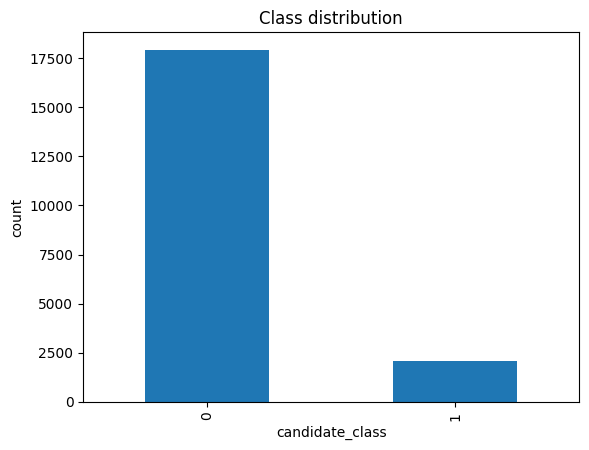

In [3]:
# Class distribution plot (run as is)
df[TARGET_COL].value_counts().plot(kind="bar")
plt.title("Class distribution"); plt.ylabel("count"); plt.show()

This dataset contains 20,000 rows and 13 numerical features about pulsar candidates. It has two imbalanced classes: 17,935 samples in class 0 and 2,065 in class 1. There are no missing or duplicated values, and all features are numeric.

## 2. Data Preparation

The workflow converts the target to binary values, applies one-hot encoding where needed, uses a stratified 80/20 train-test split, and fits the imputer and scaler on the training data only.

In [4]:
# Given: target -> 0/1 and text columns -> one-hot (run as is)
y = (df[TARGET_COL].astype(str) == str(POSITIVE_CLASS)).astype("int32").values
X_df = pd.get_dummies(df.drop(columns=[TARGET_COL]), dtype="float32")
X = X_df.values.astype("float32")
print("Features after one-hot encoding:", X.shape[1], "| positives (1):", y.sum(), "of", len(y))

# 1. Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# 2. Fill missing values using the median
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# 3. Standardize the features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Features after one-hot encoding: 13 | positives (1): 2065 of 20000
Training data shape: (16000, 13)
Testing data shape: (4000, 13)


## 3. Baseline Neural Network

The baseline model uses ReLU hidden layers and one sigmoid output neuron with `binary_crossentropy`.

In [5]:
# Helpers (run as is)
def build_model(hidden=(16, 8), dropout=0.0):
    model = keras.Sequential([keras.Input(shape=(X_train.shape[1],))])
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))          # output layer
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def plot_curves(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
    ax[0].set_title(title + " – loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
    ax[1].set_title(title + " – accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()
    print(f"final train acc = {h['accuracy'][-1]:.3f} | final val acc = {h['val_accuracy'][-1]:.3f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9495 - loss: 0.1878 - val_accuracy: 0.9878 - val_loss: 0.0534
Epoch 2/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9898 - loss: 0.0362 - val_accuracy: 0.9900 - val_loss: 0.0288
Epoch 3/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9929 - loss: 0.0228 - val_accuracy: 0.9916 - val_loss: 0.0229
Epoch 4/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9937 - loss: 0.0186 - val_accuracy: 0.9925 - val_loss: 0.0208
Epoch 5/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9945 - loss: 0.0166 - val_accuracy: 0.9928 - val_loss: 0.0197
Epoch 6/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9946 - loss: 0.0153 - val_accuracy: 0.9922 - val_loss: 0.0192
Epoch 7/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9948 - loss: 0.0144 - val_accuracy: 0.9922 - val_loss: 0.0188
Epoch 8/50
400/400 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9949 - loss: 0.0138 - val_accuracy:

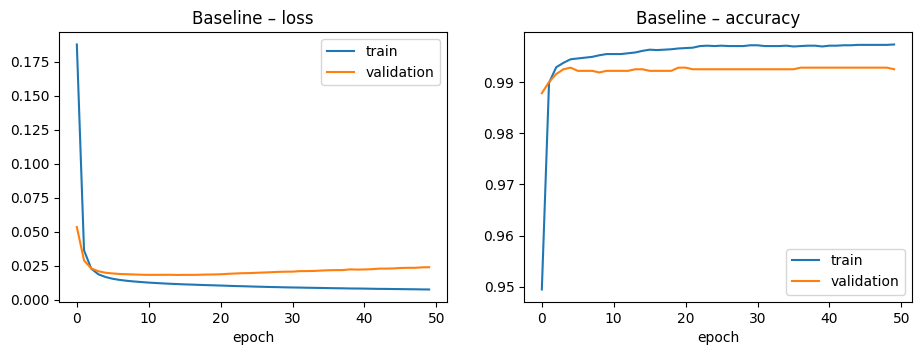

final train acc = 0.997 | final val acc = 0.993


In [6]:
# Build the baseline model
baseline = build_model(hidden=(16, 8))

# Show the model architecture
baseline.summary()

# Train the model for 50 epochs
history = baseline.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

# Plot the training and validation curves
plot_curves(history, "Baseline")

## 4. Overfitting and Regularization

The larger network is first trained without dropout to observe overfitting. A second run uses dropout and early stopping.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 256)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,801 (175.00 KB)

 Trainable params: 44,801 (175.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9425 - loss: 0.1815 - val_accuracy: 0.9825 - val_loss: 0.0545
Epoch 2/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9862 - loss: 0.0387 - val_accuracy: 0.9875 - val_loss: 0.0313
Epoch 3/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9906 - loss: 0.0244 - val_accuracy: 0.9850 - val_loss: 0.0267
Epoch 4/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9931 - loss: 0.0174 - val_accuracy: 0.9900 - val_loss: 0.0235
Epoch 5/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9956 - loss: 0.0134 - val_accuracy: 0.9900 - val_loss: 0.0248
Epoch 6/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9975 - loss: 0.0101 - val_accuracy: 0.9900 - val_loss: 0.0264
Epoch 7/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9981 - loss: 0.0077 - val_accuracy: 0.9900 - val_loss: 0.0296
Epoch 8/200
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9994 - loss: 0.0055 - val_accuracy: 0.9900 - v

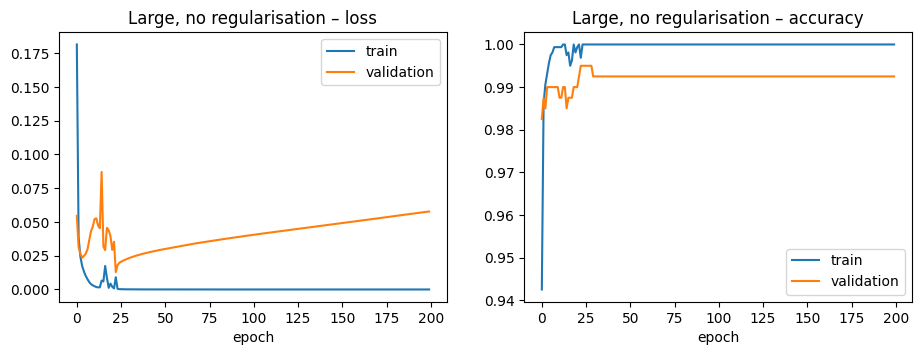

final train acc = 1.000 | final val acc = 0.993


In [7]:
# 4a: Train a large model without regularisation

# Use a smaller part of the training data to make overfitting easier to observe
X_small, _, y_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=2000,
    stratify=y_train,
    random_state=42
)

# Build the large model without dropout
big = build_model(hidden=(256, 128, 64), dropout=0.0)

big.summary()

# Train for 200 epochs
history_big = big.fit(
    X_small,
    y_small,
    epochs=200,
    batch_size=32,
    validation_split=0.2
)

# Plot the learning curves
plot_curves(history_big, "Large, no regularisation")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 256)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,801 (175.00 KB)

 Trainable params: 44,801 (175.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9728 - loss: 0.0690 - val_accuracy: 0.9928 - val_loss: 0.0193
Epoch 2/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9916 - loss: 0.0236 - val_accuracy: 0.9919 - val_loss: 0.0203
Epoch 3/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9930 - loss: 0.0218 - val_accuracy: 0.9922 - val_loss: 0.0187
Epoch 4/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9936 - loss: 0.0183 - val_accuracy: 0.9919 - val_loss: 0.0196
Epoch 5/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9945 - loss: 0.0151 - val_accuracy: 0.9919 - val_loss: 0.0182
Epoch 6/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9948 - loss: 0.0149 - val_accuracy: 0.9922 - val_loss: 0.0215
Epoch 7/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9951 - loss: 0.0136 - val_accuracy: 0.9922 - val_loss: 0.0211
Epoch 8/200
400/400 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9955 - loss: 0.0131 - val_accu

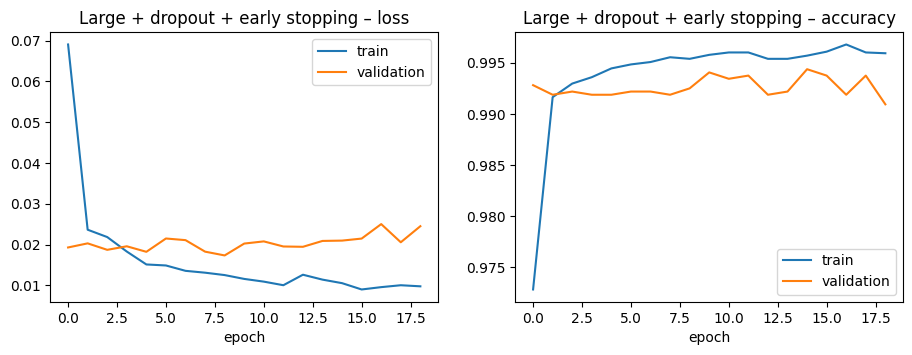

final train acc = 0.996 | final val acc = 0.991


In [8]:
# 4b: Train the large model with dropout and early stopping

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

final = build_model(
    hidden=(256, 128, 64),
    dropout=0.3
)

final.summary()

history_fix = final.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

# Plot the learning curves
plot_curves(history_fix, "Large + dropout + early stopping")


The large model starts to overfit at about epoch 25. The training loss keeps decreasing, but the validation loss starts to increase. After adding dropout and early stopping, the model stopped at epoch 19 and overfitting was reduced. The final training accuracy was 99.6%, and the validation accuracy was 99.1%.

## 5. Final Test Evaluation

The final model is evaluated on the held-out test set using a probability threshold of 0.5. Metrics include accuracy, precision, recall, F1, the confusion matrix, and the classification report.

In [9]:
# Predict probabilities on the test set
y_prob = final.predict(X_test)

# Convert probabilities to binary predictions
y_pred = (y_prob > 0.5).astype(int).ravel()

# Calculate evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-Pulsar (0)", "Pulsar (1)"],
    zero_division=0
))

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy: 0.995
Precision: 0.9758
Recall: 0.9758
F1-score: 0.9758

Confusion Matrix:
[[3577   10]
 [  10  403]]

Classification Report:
                precision    recall  f1-score   support

Non-Pulsar (0)       1.00      1.00      1.00      3587
    Pulsar (1)       0.98      0.98      0.98       413

      accuracy                           0.99      4000
     macro avg       0.99      0.99      0.99      4000
  weighted avg       0.99      0.99      0.99      4000



### Questions – answer about YOUR dataset and results
**Q1.** Why does the output layer use **1 sigmoid neuron** with **`binary_crossentropy`**? What would you change if your target had 3 classes?

We use one sigmoid neuron because our dataset has two classes: Pulsar (1) and Non-Pulsar (0). Binary crossentropy is suitable for this binary classification problem. If we had 3 classes, we would use 3 output neurons with softmax and sparse categorical crossentropy because our labels are numbers (0, 1, and 2).

**Q2.** Why are the imputer and the scaler fitted on the **training set only**? What could go wrong if they were fitted on all the data?

We fit the imputer and scaler on the training set only to avoid data leakage. If we fit them on all the data, information from the test set could affect the training process. This would make the evaluation less reliable.

**Q3.** In your problem, which error is worse: a false positive or a false negative? So which measure (precision or recall) matters most, and what value did your model get?

In pulsar detection, a false negative is worse because the model may miss a real pulsar. Therefore, recall is very important because it measures how many real pulsars the model detects. Our model achieved a recall of 97.58% for the Pulsar class.